# Imports 

In [42]:
import gc
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
from os import getcwd
from scipy.stats import binom
from scipy.sparse import csr_matrix, vstack
from IPython.display import Markdown
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from sklearn.metrics.pairwise import cosine_similarity

# Memory check (run in-between working steps if you need a sanity check)

In [38]:
%whos DataFrame

Variable             Type         Data/Info
-------------------------------------------
genome_edges         DataFrame           source  target    <...>n[56515 rows x 3 columns]
genome_matrix        DataFrame    tagId       1        2   <...>[500 rows x 1128 columns]
genome_node_df       DataFrame         movieId\n0          <...>n\n[500 rows x 1 columns]
genome_nodes         DataFrame         movieId             <...>n\n[500 rows x 2 columns]
genome_scores        DataFrame              movieId  tagId <...>8472128 rows x 3 columns]
genome_tags          DataFrame          tagId           tag<...>\n[1128 rows x 2 columns]
movie_genomes        DataFrame         movieId             <...>n\n[500 rows x 2 columns]
movie_user_vectors   DataFrame         movieId             <...>n\n[500 rows x 2 columns]
movies_data          DataFrame           movieId           <...>n[86537 rows x 3 columns]
rating_counts        DataFrame           movieId  n_ratings<...>n[83239 rows x 2 columns]
ratings_data

In [11]:
# df = ratings_data

# # Get memory usage per column in megabytes (MB)
# print(df.memory_usage(deep=True) / 1024**2)

# # Get total memory usage of the DataFrame in MB
# total_mb = df.memory_usage(deep=True).sum() / 1024**2
# print(f"Total Memory: {total_mb:.2f} MB")

Index          0.000126
userId       258.118912
movieId      258.118912
rating       258.118912
timestamp    258.118912
dtype: float64
Total Memory: 1032.48 MB


# File paths


In [4]:
data_path = "C:/Users/Kevin/Desktop/ComplexNetwork/Project/ml-latest"

# Data exploration

In [5]:
movies_data = pd.read_csv(f"{data_path}/movies.csv")

In [6]:
movies_data.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
ratings_data = pd.read_csv(f"{data_path}/ratings.csv")

In [8]:
ratings_data.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119


In [9]:
genome_tags = pd.read_csv(f"{data_path}/genome-tags.csv")
genome_scores = pd.read_csv(f"{data_path}/genome-scores.csv")

In [10]:
genome_scores.head()

,movieId,tagId,relevance
0,1,1,0.03200
1,1,2,0.02225
2,1,3,0.07000
3,1,4,0.05900
4,1,5,0.12300


# Select N most rated movies, for filtering

In [16]:
N = 500

# Count the number of ratings received by each movie.
rating_counts = (
    ratings_data.groupby("movieId")
    .size()
    .reset_index(name="n_ratings")
    .sort_values(
        ["n_ratings", "movieId"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

if not 1 <= N <= len(rating_counts):
    raise ValueError(f"N must be between 1 and {len(rating_counts):,}.")

# Select exactly N movies.
top_movies = rating_counts.head(N).copy()
top_movie_ids = top_movies["movieId"].tolist()

# Number of ratings received by the Nth selected movie.
threshold = int(top_movies.iloc[-1]["n_ratings"])

n_above = int((rating_counts["n_ratings"] > threshold).sum())
n_tied = int((rating_counts["n_ratings"] == threshold).sum())
n_selected_from_tie = N - n_above

print(f"Selected {N:,} movies.")
print(f"Fewest ratings among selected movies: {threshold:,}")
print(
    f"Selected {n_selected_from_tie:,} of {n_tied:,} movies "
    f"tied at that threshold (lowest movie IDs first)."
)

# Display the selected movies with the fewest ratings.
display(top_movies.tail(min(10, N)))

# Retain all rating rows belonging to the selected movies.
ratings_top = ratings_data.loc[
    ratings_data["movieId"].isin(top_movie_ids)
].copy()

Selected 500 movies.
Fewest ratings among selected movies: 14,905
Selected 1 of 1 movies tied at that threshold (lowest movie IDs first).


,movieId,n_ratings
490,2890,15054
491,55247,15019
492,910,15012
493,6537,14994
494,172,14988
495,4776,14966
496,4018,14950
497,2763,14947
498,1333,14930
499,3418,14905


In [17]:
ratings_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33832162 entries, 0 to 33832161
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 1.0 GB


In [18]:
ratings_top.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14516319 entries, 0 to 33832160
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 553.8 MB


In [19]:
ratings_top.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119


In [20]:
ratings_top['date'] = pd.to_datetime(ratings_top['timestamp'], unit='s', utc=True) 

# Further work with the N top movies

## Prep of main dataset

14516319

In [21]:
ratings_top.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14516319 entries, 0 to 33832160
Data columns (total 5 columns):
 #   Column     Dtype              
---  ------     -----              
 0   userId     int64              
 1   movieId    int64              
 2   rating     float64            
 3   timestamp  int64              
 4   date       datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](1), float64(1), int64(3)
memory usage: 664.5 MB


### rating and movie (inner merge -> no losses)

In [22]:
total_data = ratings_top.merge(movies_data, on="movieId", how="inner")

### Genome scores (first filtered for relavance)

<Axes: >

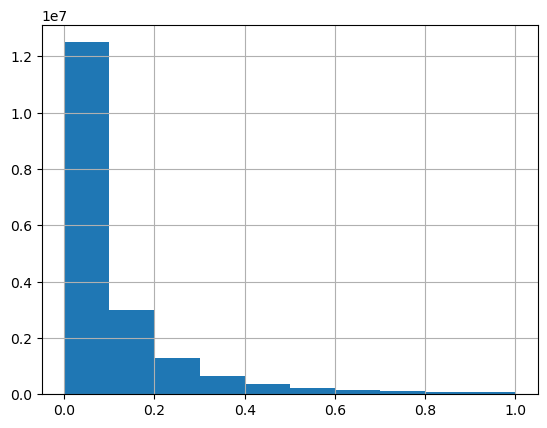

In [23]:
genome_scores["relevance"].hist()

## Visuals of movie count spread

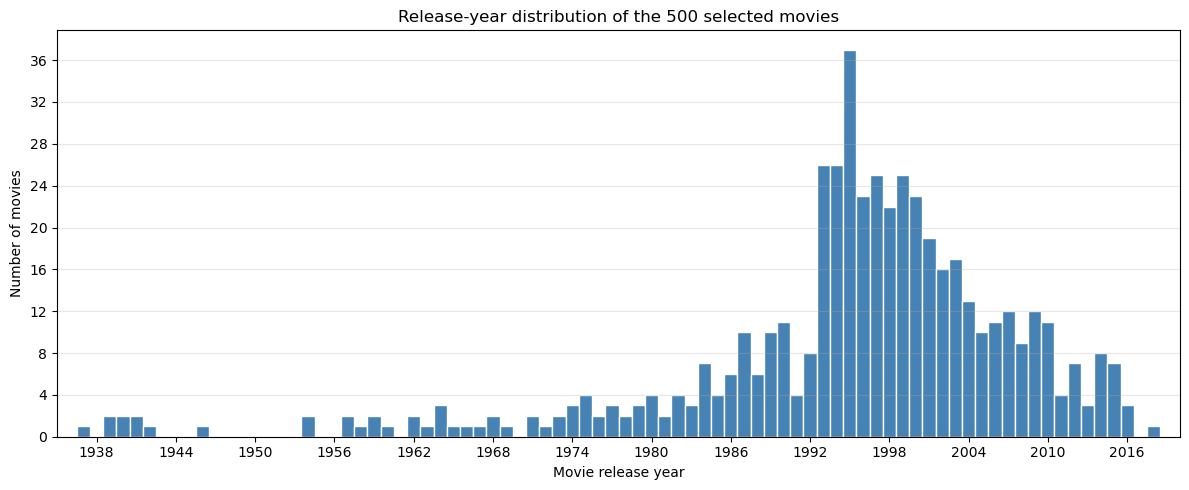

Movies without an identifiable release year: 0


In [24]:
# One row per selected movie, with its title.
selected_movies = (
    ratings_top[["movieId"]]
    .drop_duplicates()
    .merge(movies_data[["movieId", "title"]], on="movieId", how="left")
)

# Extract the release year from the final parentheses in the title.
selected_movies["release_year"] = pd.to_numeric(
    selected_movies["title"].str.extract(r"\((\d{4})\)\s*$", expand=False),
    errors="coerce"
).astype("Int64")

years = selected_movies["release_year"].dropna().astype(int)

if years.empty:
    raise ValueError("No release years could be extracted from the movie titles.")

# Integer-centred bins: one bin per release year.
bins = range(years.min(), years.max() + 2)

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(
    years,
    bins=[year - 0.5 for year in bins],
    color="steelblue",
    edgecolor="white"
)

ax.set(
    xlabel="Movie release year",
    ylabel="Number of movies",
    title=f"Release-year distribution of the {len(selected_movies)} selected movies"
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=15))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(1935,2020)

plt.tight_layout()
plt.show()

print(f"Movies without an identifiable release year: "
      f"{selected_movies['release_year'].isna().sum()}")

In [25]:
total_data.head()

,userId,movieId,rating,timestamp,date,title,genres
0,1,1,4.0,1225734739,2008-11-03 17:52:19+00:00,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,110,4.0,1225865086,2008-11-05 06:04:46+00:00,Braveheart (1995),Action|Drama|War
2,1,158,4.0,1225733503,2008-11-03 17:31:43+00:00,Casper (1995),Adventure|Children
3,1,260,4.5,1225735204,2008-11-03 18:00:04+00:00,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
4,1,356,5.0,1225735119,2008-11-03 17:58:39+00:00,Forrest Gump (1994),Comedy|Drama|Romance|War


In [26]:
print(f"Number of unique users: {len(total_data['userId'].unique())}")

Number of unique users: 309286


## Dual network creation

### Description

Two networks based on genome similarity and positive user correlation:
* Create a genome vector and create link if the cosine similarity is above a certain threshold
* Create user review vector with binary variable, add two vectors, if number of 2-values exceed threshold, create edge

Then examine the difference between these networks, should be a N=500 node network in both cases

### Code

#### Genome vectorization

In [27]:
selected_ids = np.sort(total_data["movieId"].unique())

# Temporarily arrange scores into consistently ordered columns.
genome_matrix = (
    genome_scores.loc[
        genome_scores["movieId"].isin(selected_ids),
        ["movieId", "tagId", "relevance"]
    ]
    .pivot(index="movieId", columns="tagId", values="relevance")
    .reindex(index=selected_ids, columns=range(1, 1129))
)

# Stop if any selected movie lacks a complete genome vector.
incomplete = genome_matrix.isna().any(axis=1)

if incomplete.any():
    raise ValueError(
        "Missing genome scores for movie IDs: "
        f"{genome_matrix.index[incomplete].tolist()}"
    )

# Store each movie's vector as a NumPy array in a single column.
movie_genomes = pd.DataFrame({
    "movieId": genome_matrix.index.to_numpy(),
    "genome_vector": [
        row.copy()
        for row in genome_matrix.to_numpy(dtype=float)
    ]
})

display(movie_genomes.head())

,movieId,genome_vector
0,1,"[0.0319999999999999, 0.0222499999999999, 0.07,..."
1,2,"[0.0324999999999999, 0.0319999999999999, 0.040..."
2,3,"[0.0414999999999999, 0.05525, 0.02124999999999..."
3,5,"[0.0394999999999999, 0.0519999999999999, 0.025..."
4,6,"[0.02975, 0.022, 0.0257499999999999, 0.04675, ..."


#### User rating vectorization

Text(0.5, 1.0, 'Ratings histogram')

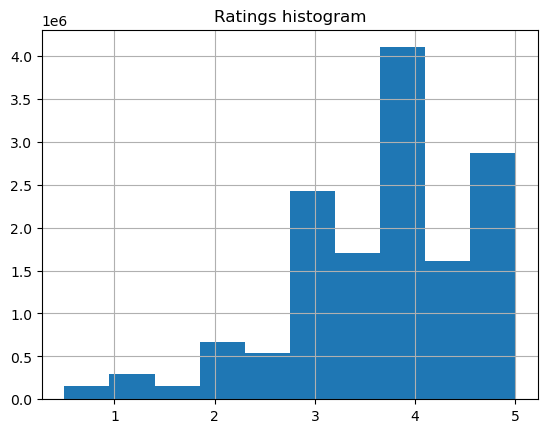

In [29]:
total_data['rating'].hist()
plt.title("Ratings histogram")

In [30]:
POSITIVE_THRESHOLD = 3.5

# Encode actual IDs into consecutive positions.
# These mappings are shared by every movie vector.
user_positions, user_ids = pd.factorize(
    total_data["userId"], sort=True
)
movie_positions, movie_ids = pd.factorize(
    total_data["movieId"], sort=True
)

if (user_positions < 0).any() or (movie_positions < 0).any():
    raise ValueError("Missing userId or movieId values.")

rating_values = total_data["rating"].to_numpy()

if not np.isfinite(rating_values).all():
    raise ValueError("Ratings contain missing or non-finite values.")

# Verify that each user–movie combination appears only once.
# Duplicate rows could otherwise silently overwrite earlier values.
if total_data.duplicated(["userId", "movieId"]).any():
    raise ValueError(
        "Duplicate user–movie pairs found. Resolve these before "
        "constructing the vectors."
    )

# Rows = movies; columns = users.
# int8 is sufficient to store -1, 0, and +1.
user_matrix = np.zeros(
    (len(movie_ids), len(user_ids)),
    dtype=np.int8
)

user_matrix[movie_positions, user_positions] = np.where(
    rating_values >= POSITIVE_THRESHOLD,
    1,
    -1
).astype(np.int8)

# Each array is a view of a row of user_matrix, avoiding a second copy.
movie_user_vectors = pd.DataFrame({
    "movieId": np.asarray(movie_ids),
    "user_vector": [row for row in user_matrix]
})

# Keep this mapping to interpret positions in the vectors.
user_mapping = pd.DataFrame({
    "user_position": np.arange(len(user_ids)),
    "userId": np.asarray(user_ids)
})

display(movie_user_vectors.head())

print(f"Movies: {len(movie_ids):,}")
print(f"Users / vector length: {len(user_ids):,}")
print(f"Matrix memory: {user_matrix.nbytes / 1e6:.1f} MB")

# Release temporary arrays used during construction.
del user_positions, movie_positions, rating_values

,movieId,user_vector
0,1,"[1, 1, 0, 0, 0, 0, 1, 0, 0, -1, 0, 1, 0, -1, 0..."
1,2,"[0, -1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, -1, 0..."
2,3,"[0, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, 0, 0,..."
3,5,"[0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0,..."
4,6,"[0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, ..."


Movies: 500
Users / vector length: 309,286
Matrix memory: 154.6 MB


#### Simple Network generation (genome)

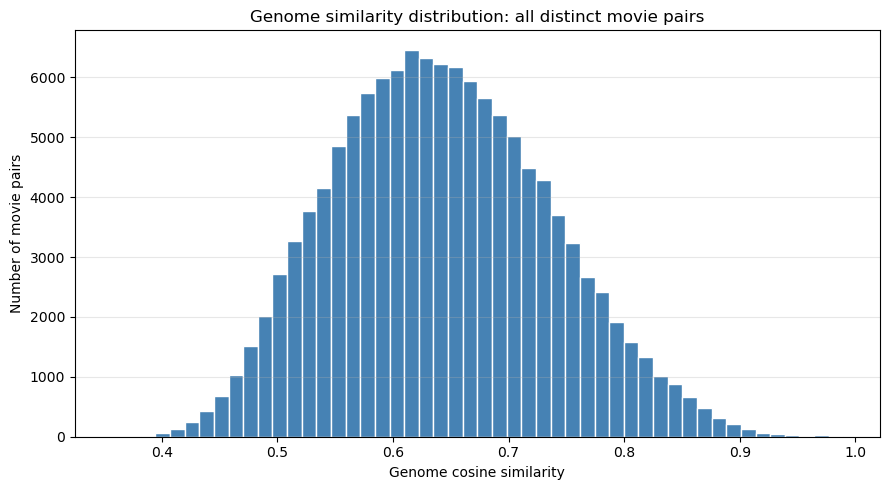

count    124750.000000
mean          0.642390
std           0.093541
min           0.356472
10%           0.522549
25%           0.573922
50%           0.638166
75%           0.706627
90%           0.767610
95%           0.803716
max           0.989635
Name: cosine_similarity, dtype: float64

In [34]:
# Keep a consistent, explicit movie ordering.
genome_nodes = movie_genomes.sort_values("movieId").reset_index(drop=True)

if genome_nodes["movieId"].duplicated().any():
    raise ValueError("movie_genomes must contain one row per movie.")

genome_ids = genome_nodes["movieId"].to_numpy()
X_genome = np.stack(genome_nodes["genome_vector"]).astype(np.float64)

if not np.isfinite(X_genome).all():
    raise ValueError("Genome vectors contain missing or non-finite values.")

if (np.linalg.norm(X_genome, axis=1) == 0).any():
    raise ValueError("Genome vectors include a zero vector.")

genome_similarity = np.clip(cosine_similarity(X_genome), -1, 1)

# Upper triangle excludes self-links and duplicate undirected pairs.
genome_i, genome_j = np.triu_indices(len(genome_ids), k=1)
genome_pair_similarities = genome_similarity[genome_i, genome_j]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    genome_pair_similarities,
    bins=50,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    xlabel="Genome cosine similarity",
    ylabel="Number of movie pairs",
    title="Genome similarity distribution: all distinct movie pairs"
)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    pd.Series(genome_pair_similarities, name="cosine_similarity")
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
)

In [36]:
GENOME_MIN_SIMILARITY = 0.65  # Retain similarities strictly above this value.

keep_genome = genome_pair_similarities > GENOME_MIN_SIMILARITY

genome_edges = pd.DataFrame({
    "source": genome_ids[genome_i[keep_genome]],
    "target": genome_ids[genome_j[keep_genome]],
    "weight": genome_pair_similarities[keep_genome]
}).sort_values("weight", ascending=False).reset_index(drop=True)

# Separate node table preserves movies with no retained links.
genome_node_df = pd.DataFrame({"movieId": genome_ids})

n_possible = len(genome_ids) * (len(genome_ids) - 1) // 2

print(f"Nodes: {len(genome_node_df):,}")
print(f"Links: {len(genome_edges):,}")
print(f"Density: {len(genome_edges) / n_possible if n_possible else 0:.4f}")

display(genome_edges.head(10))

Nodes: 500
Links: 56,515
Density: 0.4530


,source,target,weight
0,4993,5952,0.989635
1,5952,7153,0.989064
2,4993,7153,0.985708
3,40815,54001,0.985156
4,54001,69844,0.981460
5,1196,1210,0.979862
6,4896,5816,0.977033
7,40815,69844,0.976910
8,8368,54001,0.976565
9,2628,5378,0.975716


#### Simple Network generation (user)

In [39]:
MIN_SHARED_POSITIVE = 100
USER_MIN_SIMILARITY = 0.0  # Retain similarities strictly above this value.

user_nodes = movie_user_vectors.sort_values("movieId").reset_index(drop=True)

if user_nodes["movieId"].duplicated().any():
    raise ValueError("movie_user_vectors must contain one row per movie.")

user_movie_ids = user_nodes["movieId"].to_numpy()

# All vectors must use the same user ordering established previously.
vector_lengths = user_nodes["user_vector"].map(len)
if vector_lengths.nunique() != 1:
    raise ValueError("User vectors must all have the same length.")

# Rows = movies; columns = users.
# float64 prevents overflow when accumulating shared-positive counts.
B_positive = vstack(
    [
        csr_matrix((np.asarray(vector) == 1).astype(np.float64))
        for vector in user_nodes["user_vector"]
    ],
    format="csr"
)

# Inner products count shared positive raters.
shared_positive = (B_positive @ B_positive.T).toarray()

positive_counts = np.asarray(B_positive.sum(axis=1)).ravel()
denominator = np.sqrt(
    positive_counts[:, None] * positive_counts[None, :]
)

# Movies with no positive raters receive similarity zero.
user_similarity = np.divide(
    shared_positive,
    denominator,
    out=np.zeros_like(shared_positive),
    where=denominator > 0
)
user_similarity = np.clip(user_similarity, 0, 1)

# Unique undirected pairs only.
user_i, user_j = np.triu_indices(len(user_movie_ids), k=1)

pair_shared = shared_positive[user_i, user_j].astype(np.int64)
pair_similarity = user_similarity[user_i, user_j]

keep_user = (
    (pair_shared >= MIN_SHARED_POSITIVE)
    & (pair_similarity > USER_MIN_SIMILARITY)
)

user_edges = pd.DataFrame({
    "source": user_movie_ids[user_i[keep_user]],
    "target": user_movie_ids[user_j[keep_user]],
    "weight": pair_similarity[keep_user],
    "shared_positive": pair_shared[keep_user]
}).sort_values("weight", ascending=False).reset_index(drop=True)

user_node_df = pd.DataFrame({
    "movieId": user_movie_ids,
    "n_positive": positive_counts.astype(np.int64)
})

n_possible = len(user_movie_ids) * (len(user_movie_ids) - 1) // 2

print(f"Nodes: {len(user_node_df):,}")
print(f"Links: {len(user_edges):,}")
print(f"Density: {len(user_edges) / n_possible if n_possible else 0:.4f}")
print(f"Movies without positive ratings: {(positive_counts == 0).sum():,}")

display(user_edges.head(10))

Nodes: 500
Links: 124,745
Density: 1.0000
Movies without positive ratings: 0


,source,target,weight,shared_positive
0,4993,5952,0.843795,54111
1,5952,7153,0.840624,52529
2,4993,7153,0.830432,54021
3,6874,7438,0.794760,26597
4,260,1196,0.763565,55485
5,69844,81834,0.763128,12793
6,81834,88125,0.758085,12595
7,1196,1210,0.730898,46253
8,54001,69844,0.718877,11878
9,858,1221,0.715725,37423


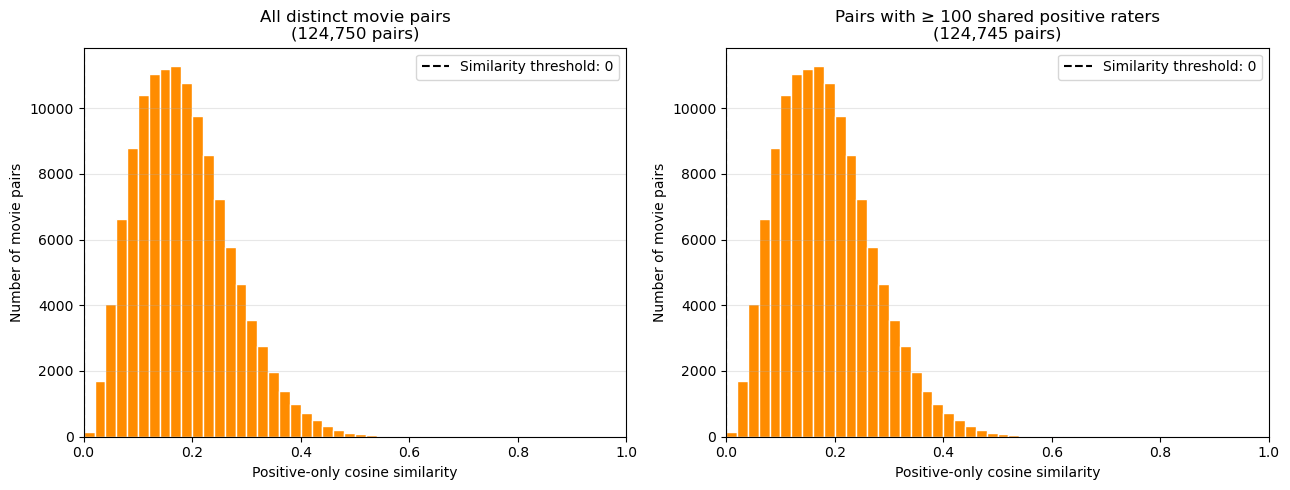

,All pairs,Minimum shared-positive count met
count,124750.000000,124745.000000
mean,0.184648,0.184654
std,0.087237,0.087232
min,0.009045,0.010340
10%,0.079945,0.079957
25%,0.119104,0.119107
50%,0.174907,0.174911
75%,0.238240,0.238241
90%,0.301754,0.301756
95%,0.342565,0.342566


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

# Common bins make the distributions easier to compare.
bins = np.linspace(0, 1, 51)

eligible = pair_shared >= MIN_SHARED_POSITIVE

distributions = [
    (pair_similarity, "All distinct movie pairs"),
    (
        pair_similarity[eligible],
        f"Pairs with ≥ {MIN_SHARED_POSITIVE:,} shared positive raters"
    )
]

for ax, (values, title) in zip(axes, distributions):
    ax.hist(values, bins=bins, color="darkorange", edgecolor="white")

    ax.axvline(
        USER_MIN_SIMILARITY,
        color="black",
        linestyle="--",
        label=f"Similarity threshold: {USER_MIN_SIMILARITY:g}"
    )

    ax.set(
        xlabel="Positive-only cosine similarity",
        ylabel="Number of movie pairs",
        title=f"{title}\n({len(values):,} pairs)",
        xlim=(0, 1)
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Numerical summaries of both distributions.
display(
    pd.DataFrame({
        "All pairs": pd.Series(pair_similarity),
        "Minimum shared-positive count met": pd.Series(
            pair_similarity[eligible]
        )
    }).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
)

### Option 1: Target-density based networks

#### Some checks (kind of redundant)

In [43]:
TARGET_DENSITIES = [0.05, 0.10, 0.15, 0.20]

# Uses the value defined previously; change it here if desired.
# MIN_SHARED_POSITIVE = 100

# Confirm that both networks contain exactly the same movies.
if set(genome_ids) != set(user_movie_ids):
    raise ValueError(
        "Genome and user networks have different movie sets. "
        "Align their movie sets and recalculate similarities first."
    )

node_ids = np.sort(np.asarray(genome_ids))
N = len(node_ids)

if N < 2:
    raise ValueError("At least two movies are required.")

N_POSSIBLE = N * (N - 1) // 2

# Full genome candidate list, before any cosine threshold.
genome_candidates = pd.DataFrame({
    "source": genome_ids[genome_i],
    "target": genome_ids[genome_j],
    "weight": genome_pair_similarities
})

# Full audience candidate list, before any cosine threshold.
user_candidates = pd.DataFrame({
    "source": user_movie_ids[user_i],
    "target": user_movie_ids[user_j],
    "weight": pair_similarity,
    "shared_positive": pair_shared
})

# Retain finite, strictly positive similarities.
genome_candidates = genome_candidates.loc[
    np.isfinite(genome_candidates["weight"])
    & (genome_candidates["weight"] > 0)
].copy()

user_candidates = user_candidates.loc[
    np.isfinite(user_candidates["weight"])
    & (user_candidates["weight"] > 0)
    & (user_candidates["shared_positive"] >= MIN_SHARED_POSITIVE)
].copy()

# Check eligibility before creating any networks.
max_required = int(np.floor(max(TARGET_DENSITIES) * N_POSSIBLE + 0.5))

for name, candidates in [
    ("genome", genome_candidates),
    ("user", user_candidates)
]:
    if len(candidates) < max_required:
        raise ValueError(
            f"{name}: only {len(candidates):,} eligible edges, "
            f"but {max_required:,} are required for the largest density."
        )

print(f"Movies: {N:,}")
print(f"Possible undirected edges: {N_POSSIBLE:,}")
print(f"Eligible genome edges: {len(genome_candidates):,}")
print(f"Eligible audience edges: {len(user_candidates):,}")

Movies: 500
Possible undirected edges: 124,750
Eligible genome edges: 124,750
Eligible audience edges: 124,745


#### Generate the networks at target-densities (see top of check-section)

In [44]:
# One shared node table, including movie metadata.
nodes_df = (
    pd.DataFrame({"movieId": node_ids})
    .merge(
        total_data[["movieId", "title", "genres"]]
        .drop_duplicates("movieId"),
        on="movieId",
        how="left",
        validate="one_to_one"
    )
)

edge_sets = {}
networks = {}
summary_rows = []

for version, candidates in [
    ("genome", genome_candidates),
    ("user", user_candidates)
]:
    # Strongest edges first; deterministic tie-breaking.
    ranked_edges = candidates.sort_values(
        ["weight", "source", "target"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    for density in TARGET_DENSITIES:
        # Closest achievable integer edge count.
        n_edges = int(np.floor(density * N_POSSIBLE + 0.5))
        name = f"{version}_{density:.0%}"

        edges = ranked_edges.head(n_edges).copy()

        # Similarity is a connection strength.
        # This defines a separate distance for weighted path calculations.
        edges["distance"] = 1.0 / edges["weight"]

        # Add every node first so isolates are preserved.
        G = nx.Graph()

        G.add_nodes_from(
            (
                row.movieId,
                {"title": row.title, "genres": row.genres}
            )
            for row in nodes_df.itertuples(index=False)
        )

        # Transfer all remaining columns as edge attributes.
        edge_attributes = [
            column for column in edges.columns
            if column not in ["source", "target"]
        ]

        for row in edges.itertuples(index=False, name=None):
            attributes = dict(zip(edge_attributes, row[2:]))
            G.add_edge(row[0], row[1], **attributes)

        G.graph.update(
            version=version,
            target_density=density,
            min_shared_positive=(
                int(MIN_SHARED_POSITIVE) if version == "user" else 0
            )
        )

        edge_sets[name] = edges.reset_index(drop=True)
        networks[name] = G

        # Describe the boundary, including ties split by edge count.
        weakest_weight = float(edges["weight"].min())
        boundary_ties_available = int(
            (ranked_edges["weight"] == weakest_weight).sum()
        )
        boundary_ties_selected = int(
            (edges["weight"] == weakest_weight).sum()
        )

        summary_rows.append({
            "network": name,
            "nodes": G.number_of_nodes(),
            "edges": G.number_of_edges(),
            "target_density": density,
            "actual_density": nx.density(G),
            "mean_degree": 2 * G.number_of_edges() / N,
            "weakest_retained_similarity": weakest_weight,
            "boundary_ties_available": boundary_ties_available,
            "boundary_ties_selected": boundary_ties_selected,
            "isolated_movies": nx.number_of_isolates(G),
            "connected_components": nx.number_connected_components(G)
        })

network_summary = pd.DataFrame(summary_rows)

display(network_summary)

,network,nodes,edges,target_density,actual_density,mean_degree,weakest_retained_similarity,boundary_ties_available,boundary_ties_selected,isolated_movies,connected_components
0,genome_5%,500,6238,0.05,0.050004,24.952,0.803719,1,1,7,8
1,genome_10%,500,12475,0.10,0.100000,49.900,0.767611,1,1,1,2
2,genome_15%,500,18713,0.15,0.150004,74.852,0.742970,1,1,0,1
3,genome_20%,500,24950,0.20,0.200000,99.800,0.723867,1,1,0,1
4,user_5%,500,6238,0.05,0.050004,24.952,0.342567,1,1,107,110
5,user_10%,500,12475,0.10,0.100000,49.900,0.301757,1,1,46,49
6,user_15%,500,18713,0.15,0.150004,74.852,0.275287,1,1,28,30
7,user_20%,500,24950,0.20,0.200000,99.800,0.255071,1,1,18,19


#### Exporting networks for easier use later

In [46]:
OUTPUT_DIR = Path("movie_networks")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Shared node table and construction summary.
nodes_df.to_csv(OUTPUT_DIR / "nodes.csv", index=False)
network_summary.to_csv(OUTPUT_DIR / "network_summary.csv", index=False)

for name, edges in edge_sets.items():
    file_stem = name.replace("%", "pct")

    edges.to_csv(
        OUTPUT_DIR / f"{file_stem}_edges.csv",
        index=False
    )

    nx.write_graphml(
        networks[name],
        OUTPUT_DIR / f"{file_stem}.graphml"
    )

print(f"Networks saved to: {OUTPUT_DIR.resolve()}")

Networks saved to: C:\Users\Kevin\Desktop\ComplexNetwork\Project\movie_networks


#### Analysis of Option 1